# <center> Employee Retention Prediction <center>
![Screenshot%202025-08-28%20125123.png](attachment:Screenshot%202025-08-28%20125123.png)

### Agenda:
1. [Frame the Problem / Business Case](#problem)
2. [Gathering the Data](#data)
3. [Data Pre-Pocessing](#processing)
4. [EDA](#eda)
5. [Feature Engineering](#engg)
6. [Model Training, Evaluation and Selection](#model)

<a id='problem'></a>

## 1. Frame the Problem / Business Case

### Background:
- Hiring and retaining employees are extremely complex tasks that require capital, time and skills
- Small business owners spend **40% of their working** hours on tasks that do **not** generate any income such as hiring
- Companies spend **15%-20%** of the employee's salary to recruit a new candidate
- An average company loses anywhere **between 1% and 2.5%** of their total revenue on the time it takes to bring a new hire up to speed
- It takes **52 days** on average to fill a position

### Problem Statement:
- You work as a data scientist at a Multi-National Corporation
- The HR team collected extensive data on their employees and approached you to develop a model that could predict which employees are more likely to quit
- The team provided you with an extensive dataset, a sample of which is provided:
    - JobInvolvement
    - Education
    - JobSatisfaction
    - PerformanceRating
    - RelationshipSatisfaction
    - WorkLifeBalance

<a id='data'></a>

## 2. Gathering the Data

In [1]:
import pandas as pd

df = pd.read_csv("Human_Resources.csv")

In [2]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


<a id='processing'></a>

In [3]:
df.shape #1470 = number of employees (rows)
         # 35 = number of columns

(1470, 35)

In [4]:
df.info() #26 int64 columns(numbers)
           #9 object columns(text/category)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [5]:
df.isnull().sum()

,0
Age,0
Attrition,0
BusinessTravel,0
DailyRate,0
Department,0
DistanceFromHome,0
Education,0
EducationField,0
EmployeeCount,0
EmployeeNumber,0


In [6]:
df["Attrition"].value_counts()# 1,233 employees stayed in the company.
                              #237 employees left the company.

,count
Attrition,
No,1233
Yes,237


In [7]:
df["Attrition"].value_counts(normalize=True) * 100 # concert into percentage


,proportion
Attrition,
No,83.877551
Yes,16.122449


## 3. Data Pre-Pocessing

In [8]:
# Check for duplicate rows
df.duplicated().sum()

np.int64(0)

In [9]:
df.nunique() #This tells us how many unique values each column has.

,0
Age,43
Attrition,2
BusinessTravel,3
DailyRate,886
Department,3
DistanceFromHome,29
Education,5
EducationField,6
EmployeeCount,1
EmployeeNumber,1470


In [10]:
df.nunique()[df.nunique() == 1]

,0
EmployeeCount,1
Over18,1
StandardHours,1


In [11]:
df.drop(
    columns=["EmployeeCount", "Over18", "StandardHours", "EmployeeNumber"],
    inplace=True
)

In [12]:
df.shape

(1470, 31)

In [13]:
df.select_dtypes(include="number").columns

Index(['Age', 'DailyRate', 'DistanceFromHome', 'Education',
       'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel',
       'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked',
       'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction',
       'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear',
       'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole',
       'YearsSinceLastPromotion', 'YearsWithCurrManager'],
      dtype='object')

In [14]:
df.select_dtypes(include = "object").columns

Index(['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender',
       'JobRole', 'MaritalStatus', 'OverTime'],
      dtype='object')

In [15]:
df.nunique()[df.select_dtypes(include="object").columns]

,0
Attrition,2
BusinessTravel,3
Department,3
EducationField,6
Gender,2
JobRole,9
MaritalStatus,3
OverTime,2


In [16]:
X = df.drop("Attrition", axis=1)
y = df["Attrition"]

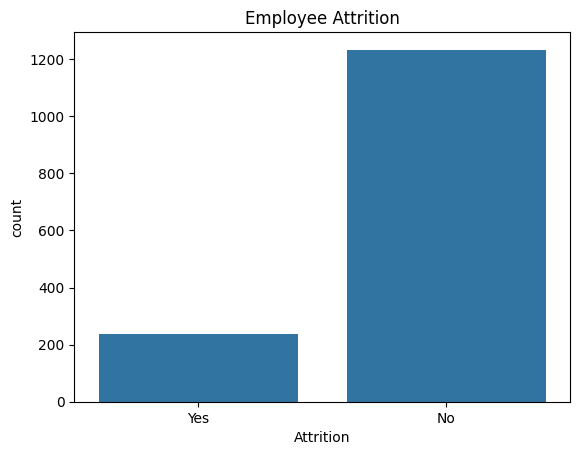

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.countplot(x="Attrition", data=df)
plt.title("Employee Attrition")
plt.show()

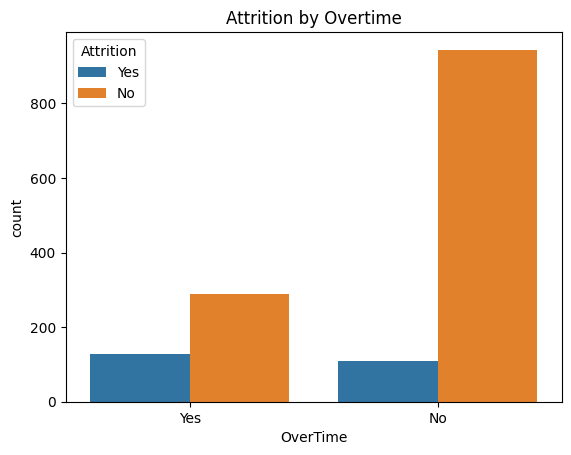

In [20]:
sns.countplot(x="OverTime", hue="Attrition", data=df)
plt.title("Attrition by Overtime")
plt.show()

## 4. Exploratory Data Analysis (EDA)

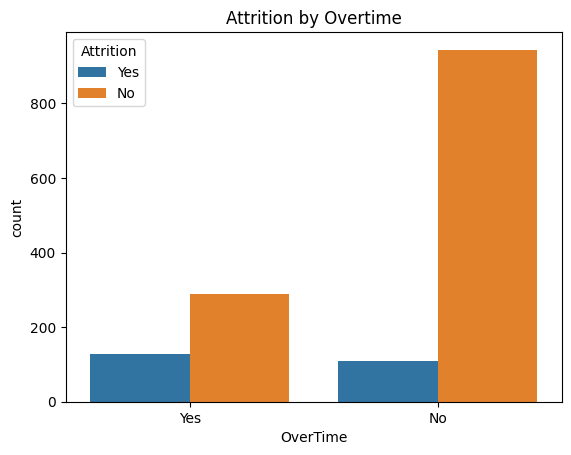

In [21]:
sns.countplot(x="OverTime", hue="Attrition", data=df)
plt.title("Attrition by Overtime")
plt.show()

In [23]:
pd.crosstab(df["OverTime"], df["Attrition"], normalize="index") * 100
#crosstab creates a table showing the relationship between two columns.
# normalize = "index" Calculate the percentage within each row.
#

Attrition,No,Yes
OverTime,,
No,89.563567,10.436433
Yes,69.471154,30.528846


In [25]:
pd.crosstab(df["JobSatisfaction"], df["Attrition"], normalize="index").mul(100).round(2)

Attrition,No,Yes
JobSatisfaction,,
1,77.16,22.84
2,83.57,16.43
3,83.48,16.52
4,88.67,11.33


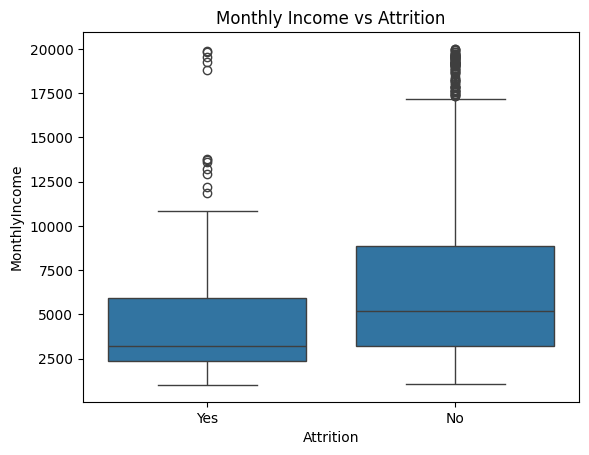

In [26]:
sns.boxplot(x="Attrition", y="MonthlyIncome", data=df)
plt.title("Monthly Income vs Attrition")
plt.show()

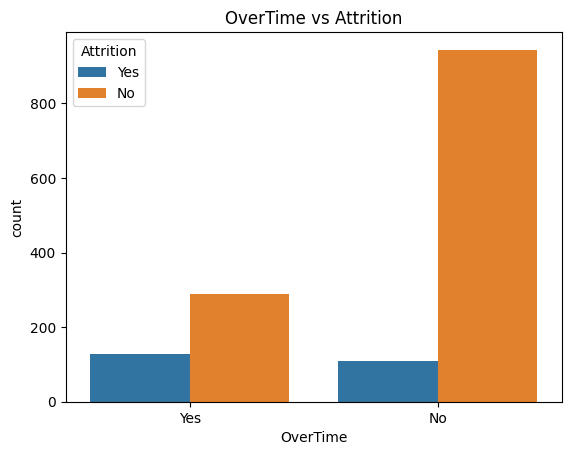

In [27]:
sns.countplot(x="OverTime", hue="Attrition", data=df)
plt.title("OverTime vs Attrition")
plt.show()

In [28]:
# Over time vs Attribution
pd.crosstab(df["OverTime"], df["Attrition"], normalize="index").mul(100).round(2)


Attrition,No,Yes
OverTime,,
No,89.56,10.44
Yes,69.47,30.53


In [29]:
# Job Level vs Attribution
pd.crosstab(df["JobLevel"], df["Attrition"], normalize="index").mul(100).round(2)

Attrition,No,Yes
JobLevel,,
1,73.66,26.34
2,90.26,9.74
3,85.32,14.68
4,95.28,4.72
5,92.75,7.25


In [30]:
# Job Satisfaction vs Attribution
pd.crosstab(df["JobSatisfaction"], df["Attrition"], normalize="index").mul(100).round(2)


Attrition,No,Yes
JobSatisfaction,,
1,77.16,22.84
2,83.57,16.43
3,83.48,16.52
4,88.67,11.33


In [ ]:
#OverTime → strong relationship 🔥
#JobLevel → lower levels have higher attrition
#JobSatisfaction → lower satisfaction has higher attrition
#MonthlyIncome → we checked using boxplot

In [31]:
# JobInvolvement vs Attribution
pd.crosstab(df["JobInvolvement"], df["Attrition"], normalize="index").mul(100).round(2)

Attrition,No,Yes
JobInvolvement,,
1,66.27,33.73
2,81.07,18.93
3,85.60,14.40
4,90.97,9.03


In [32]:
# WorkLifeBalance vs Attribution
pd.crosstab(df["WorkLifeBalance"], df["Attrition"], normalize="index").mul(100).round(2)

Attrition,No,Yes
WorkLifeBalance,,
1,68.75,31.25
2,83.14,16.86
3,85.78,14.22
4,82.35,17.65


In [33]:
# EnnvironmentSatisfaction vs Attribution

pd.crosstab(df["EnvironmentSatisfaction"], df["Attrition"], normalize="index").mul(100).round(2)

Attrition,No,Yes
EnvironmentSatisfaction,,
1,74.65,25.35
2,85.02,14.98
3,86.31,13.69
4,86.55,13.45


In [34]:
# 1️ Age vs Attrition
pd.crosstab(pd.cut(df["Age"], bins=[18,25,35,45,55,65]), df["Attrition"], normalize="index").mul(100).round(2)

Attrition,No,Yes
Age,,
"(18, 25]",65.22,34.78
"(25, 35]",80.86,19.14
"(35, 45]",90.81,9.19
"(45, 55]",88.50,11.50
"(55, 65]",82.98,17.02


In [35]:
#2️⃣ YearsAtCompany vs Attrition
pd.crosstab(pd.cut(df["YearsAtCompany"], bins=[0,2,5,10,20,40]), df["Attrition"], normalize="index").mul(100).round(2)

Attrition,No,Yes
YearsAtCompany,,
"(0, 2]",71.14,28.86
"(2, 5]",86.18,13.82
"(5, 10]",87.72,12.28
"(10, 20]",93.33,6.67
"(20, 40]",87.88,12.12


In [36]:
#3️⃣ JobRole vs Attrition
pd.crosstab(df["JobRole"], df["Attrition"], normalize="index").mul(100).round(2)

Attrition,No,Yes
JobRole,,
Healthcare Representative,93.13,6.87
Human Resources,76.92,23.08
Laboratory Technician,76.06,23.94
Manager,95.10,4.90
Manufacturing Director,93.10,6.90
Research Director,97.50,2.50
Research Scientist,83.90,16.10
Sales Executive,82.52,17.48
Sales Representative,60.24,39.76


In [37]:
#BusinessTravel vs Attrition

pd.crosstab(df["BusinessTravel"], df["Attrition"], normalize="index").mul(100).round(2)

Attrition,No,Yes
BusinessTravel,,
Non-Travel,92.00,8.00
Travel_Frequently,75.09,24.91
Travel_Rarely,85.04,14.96


In [38]:
# MaritalStatus vs Attrition
pd.crosstab(df["MaritalStatus"], df["Attrition"], normalize="index").mul(100).round(2)

Attrition,No,Yes
MaritalStatus,,
Divorced,89.91,10.09
Married,87.52,12.48
Single,74.47,25.53


In [39]:
#6 DistanceFromHome vs Attrition
pd.crosstab(pd.cut(df["DistanceFromHome"], bins=[0,5,10,20,30,50]), df["Attrition"], normalize="index").mul(100).round(2)

Attrition,No,Yes
DistanceFromHome,,
"(0, 5]",86.23,13.77
"(5, 10]",85.53,14.47
"(10, 20]",80.00,20.00
"(20, 30]",77.94,22.06


<a id='engg'></a>

## 5. Feature Engineering

                    ORIGINAL DATA
                         ↓
                 1470 × 31 columns
                         ↓
               Separate Attrition
                    ↙        ↘
                   X          y
                30 columns   Attrition
                   ↓
          Find categorical columns
                   ↓
            One-Hot Encoding
                   ↓
              44 features
                   ↓
            Ready for ML

In [40]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 31 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EnvironmentSatisfaction   1470 non-null   int64 
 9   Gender                    1470 non-null   object
 10  HourlyRate                1470 non-null   int64 
 11  JobInvolvement            1470 non-null   int64 
 12  JobLevel                  1470 non-null   int64 
 13  JobRole                   1470 non-null   object
 14  JobSatisfaction         

In [41]:
X = df.drop("Attrition", axis=1)
y = df["Attrition"]

In [42]:
X.shape, y.shape

((1470, 30), (1470,))

In [43]:
X.select_dtypes(include="object").columns

Index(['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole',
       'MaritalStatus', 'OverTime'],
      dtype='object')

In [45]:
X = pd.get_dummies(X, drop_first=True)

In [46]:
X.shape

(1470, 44)

In [47]:
X.dtypes.value_counts()

,count
int64,23
bool,21


In [48]:
X = X.astype(int)

In [49]:
X.dtypes.value_counts()

,count
int64,44


In [51]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [52]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((1176, 44), (294, 44), (1176,), (294,))

## 6. Model Training, Evaluation and Selection
*   List item



In [54]:
#Make different numerical features comparable in scale.
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()#Here we're creating the scaler tool and giving it the name:

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [55]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000) #We create our prediction machine and call it model.

model.fit(X_train_scaled, y_train) #X_train_scaled → employee information
                                   #y_train → whether each employee actually left or stayed

LogisticRegression(max_iter=1000)

####Make predictions

In [56]:

y_pred = model.predict(X_test_scaled)

In [57]:
y_pred[:10] # first 10 prediction

array(['No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No'],
      dtype=object)

In [58]:
len(y_pred)

294

###Evaluate the model

In [59]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.8605442176870748


In [60]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

          No       0.88      0.96      0.92       247
         Yes       0.62      0.34      0.44        47

    accuracy                           0.86       294
   macro avg       0.75      0.65      0.68       294
weighted avg       0.84      0.86      0.84       294



In [61]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[237  10]
 [ 31  16]]


🌳 Step 1 — Create the Decision Tree

In [62]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)
#X_train → employee information
#y_train → actual Attrition

DecisionTreeClassifier(random_state=42)

Step 2 — Make predictions

In [63]:
dt_pred = dt_model.predict(X_test)

In [64]:
dt_pred[:10]

array(['Yes', 'No', 'No', 'No', 'Yes', 'No', 'No', 'No', 'No', 'Yes'],
      dtype=object)

In [65]:
from sklearn.metrics import accuracy_score

dt_accuracy = accuracy_score(y_test, dt_pred)

print("Decision Tree Accuracy:", dt_accuracy)

Decision Tree Accuracy: 0.7653061224489796


In [66]:
print(classification_report(y_test, dt_pred))

              precision    recall  f1-score   support

          No       0.88      0.84      0.86       247
         Yes       0.31      0.38      0.34        47

    accuracy                           0.77       294
   macro avg       0.59      0.61      0.60       294
weighted avg       0.79      0.77      0.77       294



Step 1 — Create and train Random Forest

In [67]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [68]:
rf_pred = rf_model.predict(X_test)


In [69]:
rf_pred[:10]

array(['Yes', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'No', 'Yes'],
      dtype=object)

In [70]:
rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:", rf_accuracy)

Random Forest Accuracy: 0.8333333333333334


In [71]:
print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

          No       0.85      0.97      0.91       247
         Yes       0.42      0.11      0.17        47

    accuracy                           0.83       294
   macro avg       0.63      0.54      0.54       294
weighted avg       0.78      0.83      0.79       294



Step 1 — Improved Logistic Regression

In [73]:
balanced_lr = LogisticRegression(max_iter=1000, class_weight='balanced')

balanced_lr.fit(X_train_scaled, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000)

In [74]:
balanced_lr_pred = balanced_lr.predict(X_test_scaled)

In [75]:
print(classification_report(y_test, balanced_lr_pred))

              precision    recall  f1-score   support

          No       0.91      0.78      0.84       247
         Yes       0.35      0.62      0.44        47

    accuracy                           0.75       294
   macro avg       0.63      0.70      0.64       294
weighted avg       0.82      0.75      0.78       294



In [76]:
from sklearn.metrics import confusion_matrix

balanced_cm = confusion_matrix(y_test, balanced_lr_pred)

print(balanced_cm)


[[192  55]
 [ 18  29]]


"Why did you choose Balanced Logistic Regression even though its accuracy is lower?"
ANS = "The dataset had class imbalance, with fewer employees leaving than staying. The original Logistic Regression had higher accuracy, but its recall for the attrition class was only 34%. After using class_weight='balanced', recall for employees who left increased to 62%. Since identif

In [77]:
from sklearn.model_selection import GridSearchCV


In [78]:
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100]
}

In [80]:
grid_search = GridSearchCV(
    LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ),
    param_grid,
    cv=5,# Test each setting 5 times using different portions of the training data.
    scoring='recall'#"Choose the settings that give us the best Recall."
)

In [81]:
grid_search.fit(X_train_scaled, y_train)

/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_validation.py:960: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/sklearn/model_selection/_validation.py", line 949, in _score
    scores = scorer(estimator, X_test, y_test, **score_params)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_scorer.py", line 288, in __call__
    return self._score(partial(_cached_call, None), estimator, X, y_true, **_kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_scorer.py", line 380, in _score
    y_pred = method_caller(
             ^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_scorer.py", line 90, in _cached_call
   

GridSearchCV(cv=5,
             estimator=LogisticRegression(class_weight='balanced',
                                          max_iter=1000),
             param_grid={'C': [0.01, 0.1, 1, 10, 100]}, scoring='recall')

In [82]:
grid_search.best_params_

{'C': 0.01}

In [85]:
tuned_pred = grid_search.predict(X_test_scaled)

In [86]:
print(classification_report(y_test, tuned_pred))

              precision    recall  f1-score   support

          No       0.93      0.80      0.86       247
         Yes       0.40      0.70      0.51        47

    accuracy                           0.79       294
   macro avg       0.67      0.75      0.69       294
weighted avg       0.85      0.79      0.81       294



In [87]:
confusion_matrix(y_test, tuned_pred)

array([[198,  49],
       [ 14,  33]])

In [88]:
coefficients = grid_search.best_estimator_.coef_[0]

In [89]:
feature_importance = pd.DataFrame({ # Create the feature importance table
    "Feature": X_train.columns,
    "Coefficient": coefficients
})

In [90]:
feature_importance["Abs_Coefficient"] = feature_importance["Coefficient"].abs() #Add the absolute value

In [91]:
feature_importance = feature_importance.sort_values(
    by="Abs_Coefficient",
    ascending=False
)

In [92]:
feature_importance.head(10)

,Feature,Coefficient,Abs_Coefficient
43,OverTime_Yes,0.446609,0.446609
34,JobRole_Laboratory Technician,0.248570,0.248570
23,BusinessTravel_Travel_Frequently,0.235530,0.235530
4,EnvironmentSatisfaction,-0.233030,0.233030
8,JobSatisfaction,-0.221429,0.221429
11,NumCompaniesWorked,0.210269,0.210269
6,JobInvolvement,-0.202043,0.202043
42,MaritalStatus_Single,0.195106,0.195106
21,YearsSinceLastPromotion,0.191431,0.191431
0,Age,-0.190329,0.190329


###Final Model Selection

In [93]:
final_predictions = grid_search.predict(X_test_scaled)

In [94]:
final_predictions[:20]

array(['Yes', 'No', 'No', 'No', 'Yes', 'Yes', 'No', 'No', 'No', 'No',
       'No', 'No', 'Yes', 'Yes', 'Yes', 'Yes', 'No', 'No', 'Yes', 'No'],
      dtype=object)

In [95]:
pd.Series(final_predictions).value_counts()

,count
No,212
Yes,82


In [96]:
import joblib

In [97]:
joblib.dump(grid_search.best_estimator_, "attrition_model.pkl")

['attrition_model.pkl']

In [98]:
joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']

###Final Conclusion

The objective of this project was to predict employee attrition and identify employees who are likely to leave the company. After data preprocessing, feature encoding, scaling, and testing multiple machine learning models, we selected a tuned Balanced Logistic Regression model. Using class_weight='balanced' and GridSearchCV, the model achieved 79% accuracy and 70% recall for employees who leave. The most influential features included Overtime, Job Role, Frequent Business Travel, Environment Satisfaction, Job Satisfaction, and Job Involvement. This model can help HR identify employees at higher risk of attrition and take preventive actions.

## Employee Attrition Prediction – Project Summary

* **Objective:** Predict employees who are likely to leave the company.
* **Dataset:** 1,470 employees with 31 features.
* **Preprocessing:** Checked data, handled missing values, encoded categorical variables, split data into train/test sets, and scaled features.
* **Models Tested:** Logistic Regression, Decision Tree, Random Forest, and Balanced Logistic Regression.
* **Class Imbalance:** Used `class_weight='balanced'` to improve detection of employees who leave.
* **Hyperparameter Tuning:** Used GridSearchCV and selected `C = 0.01`.
* **Final Model:** Tuned Balanced Logistic Regression.
* **Performance:** 79% accuracy, 70% recall for Attrition = Yes, and 51% F1-score.
* **Important Features:** Overtime, Job Role, Business Travel, Environment Satisfaction, Job Satisfaction, and Job Involvement.
* **Business Use:** Helps HR identify employees at higher risk of leaving and take preventive actions.
